<a href="https://colab.research.google.com/github/ananyadayal/Cognitive-Computing_UCS420/blob/main/Assignment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170205          # <-- your full roll number
NAME = "Ananya"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170205   Name: Ananya   Fingerprint: DF34FD75   Tickets: 12

Ticket_ID                                                                                Ticket_Text
      T01                              The projector has stopped syncing. Is there another solution?
      T02                                                              The LMS says 'Not Submitted'.
      T03                                The Python keeps disconnecting. I have tried several times!
      T04         LMS has stopped syncing before the assignment deadline. I don't know what changed.
      T05 I keep getting logged out of the Matlab when connected to campus Wi-Fi. Please resolve it.
      T06                    I cannot access the printer since yesterday. I don't know what changed.
      T07                                                                The file is 95.5% uploaded.
      T08                                 The password is not working. It works on another computer.
      T09    

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import pandas as pd

rows = []
all_tokens = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    o = process_ticket(text)
    all_tokens += o["tokens"]
    rows.append([tid,
                 len(o["sentences"]),
                 len(o["tokens"]),
                 len(o["punct"]),
                 len(o["stops"]),
                 len(set(o["tokens"])),
                 len(o["final"])])

q1 = pd.DataFrame(rows, columns=["Ticket_ID",
                                 "Sentences",
                                 "Tokens",
                                 "Punctuation",
                                 "Stopwords",
                                 "Unique",
                                 "Final"])

total = list(q1.iloc[:, 1:].sum())
total[4] = len(set(all_tokens))
q1.loc[len(q1)] = ["TOTAL"] + total

print(q1.to_string(index=False))




Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique  Final
      T01          2      11            2          4      11      5
      T02          1       7            2          1       7      4
      T03          2      11            2          3      11      6
      T04          2      16            2          6      15      8
      T05          2      18            2          7      17      9
      T06          2      16            2          7      14      7
      T07          1       7            2          2       7      3
      T08          2      12            2          5      11      5
      T09          2      16            2          7      14      7
      T10          2      16            2          5      16      9
      T11          1       7            2          1       7      4
      T12          1       7            1          2       7      4
    TOTAL         20     144           23         50      82     71


In [6]:
##To display a selected Ticket
sel = "T02"
text = df.loc[df.Ticket_ID == sel, "Ticket_Text"].iloc[0]
o = process_ticket(text)

print(sel, ":", text)
print("Tokens:", o["tokens"])
print("Punctuation:", o["punct"])
print("Stopwords:", o["stops"])
print("Final tokens:", o["final"])

T02 : The LMS says 'Not Submitted'.
Tokens: ['the', 'lms', 'says', "'not", 'submitted', "'", '.']
Punctuation: ["'", '.']
Stopwords: ['the']
Final tokens: ['lms', 'says', "'not", 'submitted']


 **Observe**: Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# ---- patterns for re.findall ----
LONG_WORDS  = r"\b[A-Za-z]{6,}\b"                                   # longer than 5 letters
NUMBERS     = r"\b\d+(?:[.,]\d+)*\b"                                # 95.5, 2.0.1, 1,250 stay whole
CAPITALIZED = r"\b[A-Z][a-z]*(?:-[A-Z][a-z]*)*\b"                   # Wi-Fi counts as one word
VOWEL_WORDS = r"\b[aeiouAEIOU][A-Za-z]*(?:['-][A-Za-z]+)*\b"        # words starting with a vowel

# ---- patterns for re.sub ----
EMAIL = r"\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b"
URL   = r"(?:https?://|www\.)[\w\-./~%?=&#]*[\w/]"
PHONE = r"(?:\+\d{1,3}[\s-]?)?\b\d{5}[\s-]?\d{5}\b|\b0\d{3}-\d{3}-\d{4}\b"

def mask_identifiers(text):
    text = re.sub(EMAIL, "<EMAIL>", text)     # emails first, so the URL pattern cannot eat part of them
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

def show(label, text):
    print(label, ":", text)
    print("  Long words  :", re.findall(LONG_WORDS, text))
    print("  Numbers     :", re.findall(NUMBERS, text))
    print("  Capitalized :", re.findall(CAPITALIZED, text))
    print("  Vowel words :", re.findall(VOWEL_WORDS, text))
    print("  Masked      :", mask_identifiers(text))
    print()

print("===== TICKETS =====")
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    show(tid, text)

print("===== TEST_LINES =====")
for i, text in enumerate(TEST_LINES, 1):
    show(f"Line {i}", text)

# ---- count for the Observe question ----
cap_total = cap_start = cap_I = 0
for text in df["Ticket_Text"]:
    for s in sent_tokenize(text):
        cap_total += len(re.findall(CAPITALIZED, s))
        m = re.match(CAPITALIZED, s)           # first word of the sentence
        if m:
            cap_start += 1
            cap_I += (m.group() == "I")
print("Capitalized words:", cap_total,
      "| at the start of a sentence:", cap_start,
      "| of those, the word 'I':", cap_I,
      "| only because of sentence start:", cap_start - cap_I)

===== TICKETS =====
T01 : The projector has stopped syncing. Is there another solution?
  Long words  : ['projector', 'stopped', 'syncing', 'another', 'solution']
  Numbers     : []
  Capitalized : ['The', 'Is']
  Vowel words : ['Is', 'another']
  Masked      : The projector has stopped syncing. Is there another solution?

T02 : The LMS says 'Not Submitted'.
  Long words  : ['Submitted']
  Numbers     : []
  Capitalized : ['The', 'Not', 'Submitted']
  Vowel words : []
  Masked      : The LMS says 'Not Submitted'.

T03 : The Python keeps disconnecting. I have tried several times!
  Long words  : ['Python', 'disconnecting', 'several']
  Numbers     : []
  Capitalized : ['The', 'Python', 'I']
  Vowel words : ['I']
  Masked      : The Python keeps disconnecting. I have tried several times!

T04 : LMS has stopped syncing before the assignment deadline. I don't know what changed.
  Long words  : ['stopped', 'syncing', 'before', 'assignment', 'deadline', 'changed']
  Numbers     : []
  Capita

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* My tickets contain 23 capitalized words. 18 of them are the first word of a sentence, and 7 of those are just the pronoun “I”, which is always capitalized. The other 11 are capitalized only because they start a sentence: “The” (5 times), “It” (2 times), and “Is”, “Please”, “See” and “Nothing” (once each). The remaining 5 capitalized words (Not, Submitted, Python, Matlab, Wi-Fi) are capitalized for their own reasons: product names and the quoted status label. Acronyms like LMS and VPN are not matched, because the pattern needs lowercase letters after the first capital.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
from nltk.tokenize import RegexpTokenizer

TOKEN_PATTERN = r"""
    (?:https?://|www\.)[\w\-./~%?=&#]*[\w/]
  | [\w.+-]+@[\w-]+(?:\.[\w-]+)+
  | (?:\+\d{1,3}[\s-]?)?\b\d{5}[\s-]?\d{5}\b
  | \b0\d{3}-\d{3}-\d{4}\b
  | \d+(?:[.,]\d+)+
  | \w+(?:[-']\w+)*
  | [^\w\s]
"""
_tokenizer = RegexpTokenizer(TOKEN_PATTERN, flags=re.VERBOSE)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

print("===== TEST_LINES =====")
for text in TEST_LINES:
    print("my_tokenize  :", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))
    print()

print("===== TICKETS: only the ones that differ =====")
diff_ids = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    a, b = my_tokenize(text), word_tokenize(text)
    if a != b:
        diff_ids.append(tid)
        print(tid, ":", text)
        print("  my_tokenize  :", a)
        print("  word_tokenize:", b)
print("\nTickets tokenized differently:", len(diff_ids), "of", len(df), diff_ids)

===== TEST_LINES =====
my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

my_tokenize  : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']

===== 

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 4 of my 12 tickets are tokenized differently: T02, T04, T06 and T11. In T02, word_tokenize leaves the opening quote attached ('Not), while my_tokenize splits it off as its own token. In T04 and T06, don't stays one token in my_tokenize, but word_tokenize splits it into do + n't (and splits cannot into can + not in T06). In T11, my tokenizer keeps the URL as one token, while word_tokenize breaks it at the colon into https, : and //lms.thapar.edu/help. The other 8 tickets contain only plain words and punctuation, so both tokenizers give the same result.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# unique final tokens, plus a POS tag for each word taken from the full ticket (so the tagger has context)
pos_of = {}
final_words = set()
for text in df["Ticket_Text"]:
    o = process_ticket(text)
    for w, tag in pos_tag(o["tokens"]):
        pos_of.setdefault(w, tag)
    final_words.update(o["final"])
final_words = sorted(final_words)
print(len(final_words), "unique final tokens")

def to_wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

porter     = PorterStemmer()
lancaster  = LancasterStemmer()
regexp     = RegexpStemmer(r"(ing|ed|s)$", min=4)      # my rule: strip -ing, -ed and -s from words of 4+ letters
lemmatizer = WordNetLemmatizer()

rows = []
for w in final_words:
    rows.append([w, porter.stem(w), lancaster.stem(w), regexp.stem(w),
                 lemmatizer.lemmatize(w, to_wordnet_pos(pos_of.get(w, "NN")))])

q4 = pd.DataFrame(rows, columns=["Word", "Porter", "Lancaster", "Regexp", "Lemma"])
differ = q4[q4[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1]
print(len(differ), "of", len(q4), "words get different outputs:\n")
print(differ.to_string(index=False))

55 unique final tokens
33 of 55 words get different outputs:

      Word    Porter Lancaster     Regexp      Lemma
    access    access    access      acces     access
   another     anoth     anoth    another    another
assignment    assign    assign assignment assignment
    campus     campu      camp      campu     campus
   changed     chang     chang      chang     change
  computer    comput    comput   computer   computer
  deadline   deadlin   deadlin   deadline   deadline
      file      file       fil       file       file
   getting       get       get       gett        get
     https      http     https       http       http
    latest    latest    latest     latest       late
       lms        lm       lms        lms         lm
    logged       log       log       logg        log
    nobody    nobodi    nobody     nobody     nobody
   nothing      noth      noth       noth    nothing
    please     pleas     pleas     please     please
   printer   printer     print    pri

**Observe:** Give one over-stemming and one under-stemming example from your table.
*Your answer:* Over-stemming: Lancaster turns `unable` into `un` and `solution` into `solv`. It cuts so much that the stem loses the meaning and would also match unrelated words like `unit`, or `solve`, `solver` and `solved`. Under-stemming: the Regexp stemmer turns `submitted` into `submitt` and `stopped` into `stopp`, because it removes `-ed` but does not undo the doubled consonant. So these words get different stems from `submit` and `stop`, and they would not match them, whereas Porter correctly gives `submit` and `stop`

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Set  Tokens  Unique   TTR
 S1     144      82 0.569
 S2     121      76 0.628
 S3      71      55 0.775
 S4      71      52 0.732

Top 10 words in S1: [('.', 17), ('the', 11), ('i', 7), ('has', 3), ('is', 3), ('it', 3), ('stopped', 2), ('syncing', 2), ('another', 2), ('lms', 2)]

Top 10 words in S3: [('stopped', 2), ('syncing', 2), ('another', 2), ('lms', 2), ('keeps', 2), ('tried', 2), ('several', 2), ('times', 2), ("n't", 2), ('know', 2)]


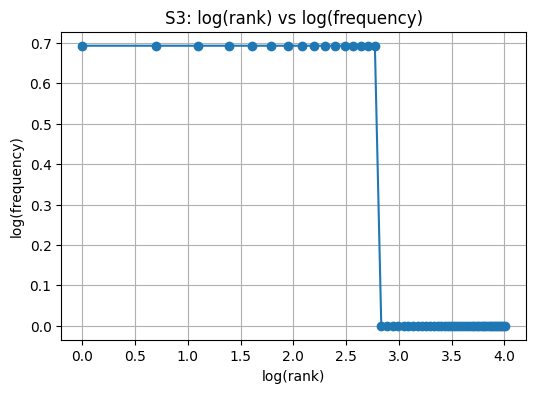

Top 5 bigrams in S1: [(('.', 'i'), 7), (('.', 'the'), 3), (('has', 'stopped'), 2), (('stopped', 'syncing'), 2), (('i', 'have'), 2)]
Top 5 bigrams in S3: [(('stopped', 'syncing'), 2), (('tried', 'several'), 2), (('several', 'times'), 2), (("n't", 'know'), 2), (('know', 'changed'), 2)]


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk import bigrams

S1 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["tokens"]]                  # all tokens
S2 = [t for t in S1 if not is_punct(t)]                                                          # no punctuation
S3 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["final"]]                    # final tokens
S4 = [PorterStemmer().stem(t) for t in S3]                                                       # S3 after Porter

stats = pd.DataFrame(
    [[name, len(s), len(set(s)), round(len(set(s)) / len(s), 3)]
     for name, s in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]],
    columns=["Set", "Tokens", "Unique", "TTR"])
print(stats.to_string(index=False))

print("\nTop 10 words in S1:", Counter(S1).most_common(10))
print("\nTop 10 words in S3:", Counter(S3).most_common(10))

# Zipf-style plot for S3
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(freqs), "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: log(rank) vs log(frequency)")
plt.grid(True)
plt.show()

print("Top 5 bigrams in S1:", Counter(bigrams(S1)).most_common(5))
print("Top 5 bigrams in S3:", Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR is unique tokens divided by total tokens. It goes S1 0.569, S2 0.628, S3 0.775, S4 0.732. From S1 to S2, removing punctuation drops 23 tokens but only 6 unique types, because marks like . repeat a lot, so TTR rises. From S2 to S3, removing stopwords takes out 50 tokens but only 21 types, because words like the and i repeat a lot, so TTR rises again. From S3 to S4, Porter stemming keeps the token count the same but merges variants (for example keep and keeps), so the unique count falls from 55 to 52 and TTR drops to 0.732. So the first two steps raise TTR because they remove repeated filler, and stemming lowers it because it merges word forms.

---
## 6. Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
(c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

*Answer:*
(a) TTR is the number of unique tokens divided by the total number of tokens. In my data it goes from 0.569 (S1) to 0.628 (S2), 0.775 (S3) and 0.732 (S4). Removing punctuation and stopwords throws away lots of repeated tokens like the full stop, “the” and “i”, but only a few unique ones, so the ratio goes up. Stemming then merges word forms like keep and keeps, so the unique count drops from 55 to 52 while the token count stays at 71, and TTR falls a little.

(b) Take ticket T04, “I don’t know what changed.” The word_tokenize function splits don’t into do and n’t, but my tokenizer keeps don’t as one token, because my pattern allows an apostrophe inside a word. Another difference is in T11, where my tokenizer keeps the whole URL as one token, and word_tokenize breaks it into https, a colon and //lms.thapar.edu/help.

(c) The Lancaster stemmer turns unable into un. That cuts off almost the entire word, so the meaning is gone, and the stem would also match unrelated words like unit or under. Another case is solution, which becomes solv and gets mixed up with solve and solver.

(d) Take tried in tickets T03 and T10. Porter stemming turns it into tri, which isn’t a real word. The POS-aware lemmatizer sees that tried is a verb and gives try, which keeps the meaning and is a proper word. The same happens with replied, where the stemmer gives repli but the lemmatizer gives reply.